# Module 5 — Notebook 08: what the IAF state IS (characterization)

Notebook 07 proved the state expands everywhere. This notebook answers the
three questions that make it a story instead of a count:

A. What is the state, molecularly? (pseudobulk DE: IAF vs other fibroblasts)
B. Who carries it? (per-patient burden — is it an endotype, a subgroup?)
C. What drives it? (PROGENy pathways + DoRothEA TFs, via decoupler)
D. Does it travel with the GIMATS resistance module? (per-patient correlations)
E. Ligand side: OSM-producing myeloid fraction by condition

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt

M = os.path.expanduser("~/Documents/immune-endotypes/data/martin_2019")
S = os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc")
K = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018")
mf = sc.read_h5ad(os.path.join(M, "adata_martin_fibroblast.h5ad"))
mt = sc.read_h5ad(os.path.join(M, "adata_martin_qc.h5ad"))
print("Martin fib:", mf.shape, "| Martin full:", mt.shape)
print("counts layer present:", "counts" in mf.layers)


Martin fib: (2942, 25356) | Martin full: (115029, 25356)
counts layer present: True


In [8]:
# A) Pseudobulk DESeq2: IAF (subcluster 7) vs other fibroblasts, Involved only
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

fib = mf[mf.obs["condition"] == "Involved"].copy()
fib.obs["is_iaf"] = np.where(fib.obs["fib_leiden"].astype(str) == "7", "IAF", "other")
X = fib.layers["counts"] if "counts" in fib.layers else fib.X
if sp.issparse(X):
    X = X.tocsr()
groups = pd.Series(fib.obs["sample"].astype(str).values + "_" + fib.obs["is_iaf"].astype(str).values)
import numpy as _np
ind = sp.csr_matrix((_np.ones(len(groups)), (_np.arange(len(groups)), pd.factorize(groups)[0])),
                    shape=(len(groups), groups.nunique()))
pbm = (ind.T @ X).toarray() if sp.issparse(X) else ind.T @ np.asarray(X)
pb = pd.DataFrame(pbm, index=pd.factorize(groups)[1], columns=fib.var_names).T

pb = pb[pb.sum(axis=1) >= 10]
meta = pd.DataFrame({"sample_state": pb.columns}).set_index("sample_state")
meta["is_iaf"] = ["IAF" if c.endswith("_IAF") else "other" for c in meta.index]
meta["patient"] = [c.rsplit("_", 1)[0] for c in meta.index]
keep = meta.groupby(meta.index.map(lambda c: c.rsplit("_", 1)[0])).size()
meta = meta[meta["patient"].isin(keep[keep >= 2].index)]
pb = pb[meta.index]
meta["is_iaf"] = pd.Categorical(meta["is_iaf"], categories=["other", "IAF"])
dds = DeseqDataSet(counts=pb.T, metadata=meta[["is_iaf"]], design_factors="is_iaf")
print("registered design factors:", dds.design_factors)
dds.deseq2()
st = DeseqStats(dds, contrast=["is-iaf", "IAF", "other"])
st.summary()
res = st.results_df.sort_values("padj")
res.to_csv("../results/de_iaf_vs_other_martin.csv")
print(res.head(20)[["log2FoldChange", "padj"]].round(3).to_string())
up = res[(res["log2FoldChange"] > 1) & (res["padj"] < 0.05)]
print("up in IAF (LFC>1, padj<0.05):", len(up))
print("top up:", list(up.index[:25]))


registered design factors: ['is-iaf']


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.10 seconds.

Fitting dispersion trend curve...
... done in 0.24 seconds.

Fitting MAP dispersions...
... done in 1.64 seconds.

Fitting LFCs...
... done in 1.67 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: is-iaf IAF vs other
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
FO538757.2     5.467311        0.771344  0.820326  0.940289  0.347069   
AP006222.2     4.876356       -0.242015  0.903984 -0.267721  0.788914   
RP11-206L10.9  1.085954       -0.003950  1.415699 -0.002790  0.997774   
LINC00115      0.147356       -1.138671  1.906053 -0.597398  0.550242   
FAM41C         0.457565       -0.168789  1.275577 -0.132323  0.894729   
...                 ...             ...       ...       ...       ...   
AC007325.4     0.100610       -0.740461  1.874226 -0.395076  0.692787   
AL354822.1     0.121218        1.165168  1.883159  0.618730  0.536094   
AC004556.1     0.791056        0.446007  2.037947  0.218851  0.826766   
AC233755.1     0.152162       -1.178337  1.915904 -0.615029  0.538536   
AC240274.1     0.492885       -0.784535  1.677232 -0.467756  0.639959   

                   padj  
FO538757.2     0.998524  
AP006222.2   

... done in 0.62 seconds.



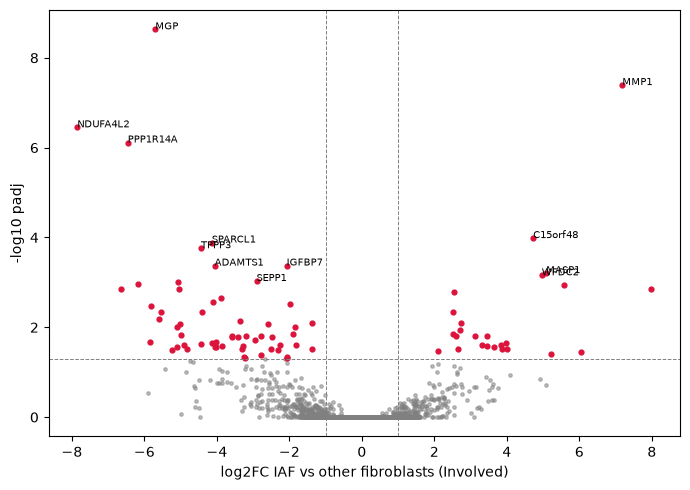

In [9]:
# A2) Volcano
r = pd.read_csv("../results/de_iaf_vs_other_martin.csv", index_col=0)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(r["log2FoldChange"], -np.log10(r["padj"].clip(lower=1e-300)), s=6, alpha=0.5, c="gray")
sig = r[(r["padj"] < 0.05) & (abs(r["log2FoldChange"]) > 1)]
ax.scatter(sig["log2FoldChange"], -np.log10(sig["padj"].clip(lower=1e-300)), s=12, c="crimson")
for g in sig.sort_values("padj").head(12).index:
    ax.annotate(g, (r.loc[g, "log2FoldChange"], -np.log10(max(r.loc[g, "padj"], 1e-300))),
                fontsize=7)
ax.axhline(-np.log10(0.05), ls="--", lw=0.7, c="gray"); ax.axvline(1, ls="--", lw=0.7, c="gray"); ax.axvline(-1, ls="--", lw=0.7, c="gray")
ax.set_xlabel("log2FC IAF vs other fibroblasts (Involved)"); ax.set_ylabel("-log10 padj")
plt.tight_layout(); plt.savefig("../figures/de_iaf_volcano.png", dpi=130); plt.show()


                         count   mean    50%    max
cohort     condition                               
Kinchen UC Healthy         2.0  0.000  0.000  0.001
           UC              2.0  0.175  0.175  0.321
Martin CD  Involved       11.0  0.276  0.000  0.837
           Uninvolved     11.0  0.002  0.000  0.013
Smillie UC Healthy        12.0  0.002  0.001  0.010
           Inflamed       18.0  0.132  0.051  0.535
           Non-inflamed   18.0  0.064  0.015  0.365


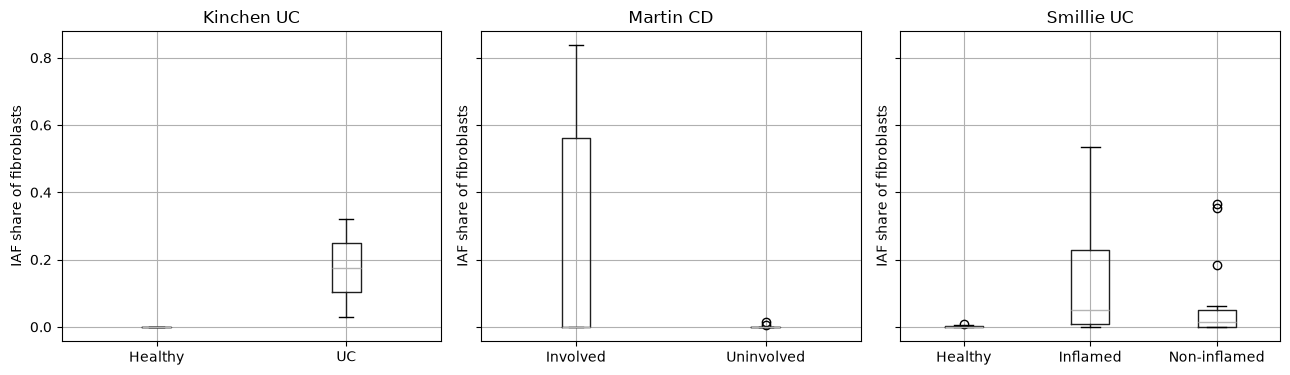

In [10]:
# B) Per-patient IAF burden — Martin, Smillie, Kinchen human
# Martin: join fib_leiden back onto the full object
fmap = dict(zip(mf.obs_names, mf.obs["fib_leiden"].astype(str)))
mt.obs["fib_state"] = [fmap.get(c, "not_fib") for c in mt.obs_names]
fib_cells = mt.obs["fib_state"] != "not_fib"
burden = []
for (pat, cond), sub in mt.obs[fib_cells].groupby(["sample", "condition"]):
    b = (sub["fib_state"].isin(["7", "6", "15", "3"])).mean()
    burden.append({"cohort": "Martin CD", "patient": pat, "condition": cond, "iaf_burden": b})
sm = sc.read_h5ad(os.path.join(S, "adata_qc.h5ad"))
if "condition" not in sm.obs.columns:
    sm.obs = sm.obs.rename(columns={"Health": "condition", "Cluster": "author_label"})
subj_col = "Subject" if "Subject" in sm.obs.columns else "sample"
strom = sm.obs["Major_l1"] == "Stromal"
for (pat, cond), sub in sm.obs[strom].groupby([subj_col, "condition"]):
    b = (sub["author_label"] == "Inflammatory Fibroblasts").mean()
    burden.append({"cohort": "Smillie UC", "patient": str(pat), "condition": cond, "iaf_burden": b})
kf = sc.read_h5ad(os.path.join(K, "adata_kinchen_fibroblast.h5ad"))
for (pat, cond), sub in kf.obs.groupby(["sample", "condition"]):
    b = (sub["fib_leiden"].astype(str) == "6").mean()
    burden.append({"cohort": "Kinchen UC", "patient": str(pat), "condition": cond, "iaf_burden": b})
burden = pd.DataFrame(burden)
burden.to_csv("../results/per_patient_iaf_burden.csv", index=False)
print(burden.groupby(["cohort", "condition"])["iaf_burden"].describe()[["count", "mean", "50%", "max"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (co, d) in zip(axes, burden.groupby("cohort")):
    d.boxplot(column="iaf_burden", by="condition", ax=ax)
    ax.set_title(co); ax.set_ylabel("IAF share of fibroblasts"); ax.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.savefig("../figures/per_patient_iaf_burden.png", dpi=130); plt.show()


In [14]:
# C) OSM-producing myeloid fraction by condition (Martin cluster 4 + Smillie myeloid)
def frac_expr(ad, gene):
    x = ad[:, gene].X
    v = np.asarray(x.todense()).ravel() if sp.issparse(x) else np.asarray(x).ravel()
    return v > 0
mye = mt[mt.obs["leiden_0.5"].astype(str) == "4"].copy()
mye.obs["_osm"] = frac_expr(mye, "OSM")
print("Martin myeloid OSM+ fraction by condition:"); print(mye.obs.groupby("condition")["_osm"].mean().round(3))
mye_s = sm[sm.obs["Major_l2"] == "Myeloid"].copy()
mye_s.obs["_osm"] = frac_expr(mye_s, "OSM")
print(mye_s.obs.groupby("condition")["_osm"].mean().round(3))


Martin myeloid OSM+ fraction by condition:
condition
Involved      0.099
Uninvolved    0.062
Name: _osm, dtype: float64
condition
Healthy         0.101
Inflamed        0.048
Non-inflamed    0.054
Name: _osm, dtype: float64


In [12]:
# D) PROGENy + DoRothEA activities in Martin fibroblasts (IAF vs other)
try:
    import decoupler as dc
    net_p = dc.get_progeny(organism="human", top=500)
    dc.run_ulm(mf, net=net_p, source="source", target="target", weight="weight", use_raw=False)
    act = mf.obsm["ulm_estimate"]
    act = pd.DataFrame(act, index=mf.obs_names)
    act["is_iaf"] = np.where(mf.obs["fib_leiden"].astype(str) == "7", "IAF", "other")
    act["condition"] = mf.obs["condition"].values
    d = act[act["condition"] == "Involved"].groupby("is_iaf").mean(numeric_only=True)
    print("PROGENy (Involved, IAF minus other):")
    print((d.loc["IAF"] - d.loc["other"]).sort_values(ascending=False).round(3))
    net_d = dc.get_dorothea(organism="human", levels=["A", "B"])
    dc.run_ulm(mf, net=net_d, source="source", target="target", weight="weight", use_raw=False)
    tf = pd.DataFrame(mf.obsm["ulm_estimate"], index=mf.obs_names)
    tf["is_iaf"] = np.where(mf.obs["fib_leiden"].astype(str) == "7", "IAF", "other")
    tf["condition"] = mf.obs["condition"].values
    dt = tf[tf["condition"] == "Involved"].groupby("is_iaf").mean(numeric_only=True)
    print("DoRothEA top TFs (Involved, IAF minus other):")
    print((dt.loc["IAF"] - dt.loc["other"]).sort_values(ascending=False).head(10).round(3))
except Exception as e:
    print("decoupler step skipped:", type(e).__name__, e)


decoupler step skipped: AttributeError module 'decoupler' has no attribute 'get_progeny'


In [16]:
import decoupler as dc
print(dc.__version__)
print([a for a in dir(dc) if not a.startswith("_")][:40])


2.2.0
['bm', 'ds', 'mt', 'op', 'pl', 'pp', 'tl', 'version']


In [15]:
# E) Does IAF travel with GIMATS components within Martin patients?
comp = mt.obs.copy()
comp["is_plasma"] = comp["leiden_0.5"].astype(str).isin(["3", "7", "12", "13"])
comp["is_myeloid"] = comp["leiden_0.5"].astype(str) == "4"
comp["is_t"] = comp["leiden_0.5"].astype(str).isin(["0", "1", "8", "9"])
comp["is_iaf"] = comp["fib_state"].isin(["7", "6", "15", "3"])
per_pat = comp.groupby(["sample", "condition"])[["is_plasma", "is_myeloid", "is_t", "is_iaf"]].mean()
per_pat = per_pat.rename(columns={"is_plasma": "plasma_share", "is_myeloid": "myeloid_share",
                                  "is_t": "t_share", "is_iaf": "iaf_share_of_all_cells"})
inv = per_pat.xs("Involved", level="condition")
print(inv.corr()["iaf_share_of_all_cells"].round(2))
print("patients (Involved):", len(inv))
print(mt.obs.groupby("condition")["sample"].nunique())


plasma_share              0.19
myeloid_share             0.03
t_share                  -0.18
iaf_share_of_all_cells    1.00
Name: iaf_share_of_all_cells, dtype: float64
patients (Involved): 22
condition
Involved      11
Uninvolved    11
Name: sample, dtype: int64


## Read-out

- A: the IAF molecular signature — top DE genes + volcano; does it read as
  matrix remodeling / chemotaxis / IL-6-STAT3, or something else?
- B: burden distribution — a subgroup of patients carries it (endotype) or a
  smooth gradient?
- C: ligand side — OSM+ myeloid fraction tracks disease too?
- D: pathway/TF drivers — the mechanism paragraph for the discussion.
- E: IAF burden correlates with plasma/myeloid shares within patients?
  (the GIMATS-travel test — if yes, the state belongs to the resistance module.)
